# Курс Data Science. Дипломный проект. Задача классификации.
## «Модель прогнозирования остановки на питстоп в чемпионате автогонок в классе "Формула1"»

## 1. Разведывательный анализ

### Описание данных:
* 'Driver' — пилот;
* 'LapNumber' текуший номер круга гонки;
* 'Compound' — состав покрышек;
* 'Stint' — номер используемого комплекта покрышек;
* 'TyreLife' — количество кругов, пройденных на данном комплекте покрышек;
* 'Position' — текущая позиция пилота в гонке;
* 'LapTime ' — время прохождения данного круга;
* 'Race' — название трассы, где проходит этап;
* 'Year' — год проведения этапа гонки;
* 'LapTime_Delta' — разница во времени прохождения данного круга с предыдущим;
* 'Cumulative_Degradation' — показатель износа шины на данном круге;
* 'PitStop' — случилась ли остановка на питстоп на данном круге;
* 'PitNextLap' — будет ли остановка на следующем круге, целевая переменная;
* 'RaceProgress' — прогресс гонки;
* 'Normalized_TyreLife' нормализованное количество кругов, пройденных на данном комплекте покрышек;
* 'Position_Change' — изменение позиций на данном круге.
* 'Prev_TyreLife' — количество кругов, пройденных на данном комплекте покрышек на предыдущем круге;

Данный датасет скачан с платформы Kaggle по адресу https://www.kaggle.com/datasets/sohailkhanlml/f1-strategy-dataset
Он представляет из себя реальные значения вышеописанных параметров, полученных во время тестов и гонок болидов Формулы1.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import chi2
import category_encoders as ce
import pickle
#отключим оповещения
import warnings
warnings.filterwarnings("ignore")

### 0. Знакомство с данными.

In [34]:
df = pd.read_csv('data/f1_strategy_dataset_v6.csv')
df.head(3)

,Driver,LapNumber,Compound,Stint,TyreLife,Position,LapTime (s),Race,Year,LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,RaceProgress,Normalized_TyreLife,Position_Change,Prev_TyreLife
0,ALB,1,MEDIUM,1,2.0,17,100.625,Abu Dhabi Grand Prix,2023,0.000,0.000,0,0.0,0.017241,0.117647,0.0,NaN
1,ALB,2,MEDIUM,1,3.0,18,93.560,Abu Dhabi Grand Prix,2023,-7.065,-7.065,0,0.0,0.034483,0.176471,-1.0,2.0
2,ALB,3,MEDIUM,1,4.0,18,91.768,Abu Dhabi Grand Prix,2023,-1.792,-8.857,0,0.0,0.051724,0.235294,0.0,3.0


### 1.1 Пропуски и дубликаты

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101371 entries, 0 to 101370
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Driver                  101371 non-null  object 
 1   LapNumber               101371 non-null  int64  
 2   Compound                101305 non-null  object 
 3   Stint                   101371 non-null  int64  
 4   TyreLife                101371 non-null  float64
 5   Position                101371 non-null  int64  
 6   LapTime (s)             101371 non-null  float64
 7   Race                    101371 non-null  object 
 8   Year                    101371 non-null  int64  
 9   LapTime_Delta           101371 non-null  float64
 10  Cumulative_Degradation  101371 non-null  float64
 11  PitStop                 101371 non-null  int64  
 12  PitNextLap              101370 non-null  float64
 13  RaceProgress            101371 non-null  float64
 14  Normalized_TyreLife 

Имеем пропуски в признаке "Prev_TyreLife". Подозреваем связь этого признака с признаком "TyreLife". Проверим это предположение.

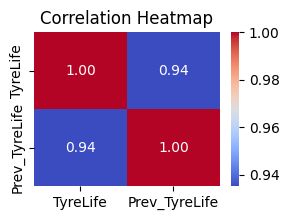

In [36]:
# Корреляция признаков TyreLife и Prev_TyreLife
plt.figure(figsize=(3,2))
sns.heatmap(df[['TyreLife','Prev_TyreLife']].corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

Можем удалить один из этих признаков, что не должно сильно повлиять на предсказательную модель.
Удалим признак, в котором имеются пропуски - "Prev_TyreLife".

In [37]:
df = df.drop(['Prev_TyreLife'], axis=1)

Также имеем пропуски в признаке 'Compound'. Посмотрим на них поближе.

In [38]:
df[df.isna().any(axis=1)].sort_values(by='LapNumber')

,Driver,LapNumber,Compound,Stint,TyreLife,Position,LapTime (s),Race,Year,LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,RaceProgress,Normalized_TyreLife,Position_Change
95659,STR,30,NaN,5,7.0,14,103.833,Monaco Grand Prix,2022,0.000,0.000,0,0.0,0.416667,0.170732,1.0
95660,STR,31,NaN,5,8.0,14,84.515,Monaco Grand Prix,2022,-19.318,-19.318,0,0.0,0.430556,0.195122,0.0
95661,STR,32,NaN,5,9.0,14,97.937,Monaco Grand Prix,2022,13.422,-5.896,0,0.0,0.444444,0.219512,0.0
95662,STR,33,NaN,5,10.0,14,84.605,Monaco Grand Prix,2022,-13.332,-19.228,0,0.0,0.458333,0.243902,0.0
95663,STR,34,NaN,5,11.0,14,82.704,Monaco Grand Prix,2022,-1.901,-21.129,0,0.0,0.472222,0.268293,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81181,RUS,67,NaN,3,30.0,4,69.757,Austrian Grand Prix,2022,-6.821,-114.403,0,0.0,0.930556,0.882353,0.0
81182,RUS,68,NaN,3,31.0,4,69.778,Austrian Grand Prix,2022,-7.102,-114.382,0,0.0,0.944444,0.911765,0.0
81183,RUS,69,NaN,3,32.0,4,69.739,Austrian Grand Prix,2022,-7.010,-114.421,0,0.0,0.958333,0.941176,0.0
81184,RUS,70,NaN,3,33.0,4,69.489,Austrian Grand Prix,2022,-7.296,-114.671,0,0.0,0.972222,0.970588,0.0


Основываясь на реальных данных с сайта f1news.ru, пропуски везде меняем на значение 'HARD'

In [39]:
df['Compound'] = df['Compound'].fillna('HARD')
df['Compound'].unique() # проверяем, что в признаке не осталось пропусков

array(['MEDIUM', 'HARD', 'SOFT', 'INTERMEDIATE', 'WET'], dtype=object)

Смотрим на оставшийся пропуск в столбце "PitNextLap".

In [40]:
df[df.isna().any(axis=1)]

,Driver,LapNumber,Compound,Stint,TyreLife,Position,LapTime (s),Race,Year,LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,RaceProgress,Normalized_TyreLife,Position_Change
101370,ZHO,56,HARD,3,33.0,14,103.881,United States Grand Prix,2022,21.39,-89.756,0,NaN,0.777778,0.970588,4.0


Согласно данным того же сайта - это последний круг гонки, поэтому заполняем значением '0'. Если это последний круг, на следующем круге не может быть питстопа.

In [41]:
df['PitNextLap'] = df['PitNextLap'].fillna(0)

Проверим наш датасет на дубликаты.

In [42]:
df.duplicated().sum()

0

Дубликатов нет.

### 1.2 Выбросы в данных.

Посмотрим внимательно на числовые признаки.

In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LapNumber,101371.0,30.444841,18.146942,1.000000,15.000000,30.000000,45.000000,78.000
Stint,101371.0,2.046394,0.948797,1.000000,1.000000,2.000000,3.000000,8.000
TyreLife,101371.0,14.549339,10.313385,1.000000,7.000000,13.000000,20.000000,78.000
Position,101371.0,9.759132,5.406456,1.000000,5.000000,10.000000,14.000000,20.000
LapTime (s),101371.0,92.587188,33.231414,67.012000,82.021000,91.167000,99.356000,2526.253
Year,101371.0,2023.589685,1.098518,2022.000000,2023.000000,2024.000000,2025.000000,2025.000
LapTime_Delta,101371.0,-0.203891,45.344910,-2403.895000,-7.253000,-0.027000,5.705000,2433.472
Cumulative_Degradation,101371.0,-29.550051,70.235759,-274.564000,-51.054500,-21.678000,-3.725500,2412.431
PitStop,101371.0,0.028815,0.167287,0.000000,0.000000,0.000000,0.000000,1.000
PitNextLap,101371.0,0.028815,0.167287,0.000000,0.000000,0.000000,0.000000,1.000


На распределениях признаков Cumulative_Degradation, LapTime_Delta, LapTime (s) видим странные значения по времени, 
не свойственные для времени прохождения круга на машине f1.
Это около 2500 секунд, что равно примерно 42 минутам. Время как обычное время прохождения круга порядка 1,5 минут.

Посмотрим графики распределения.

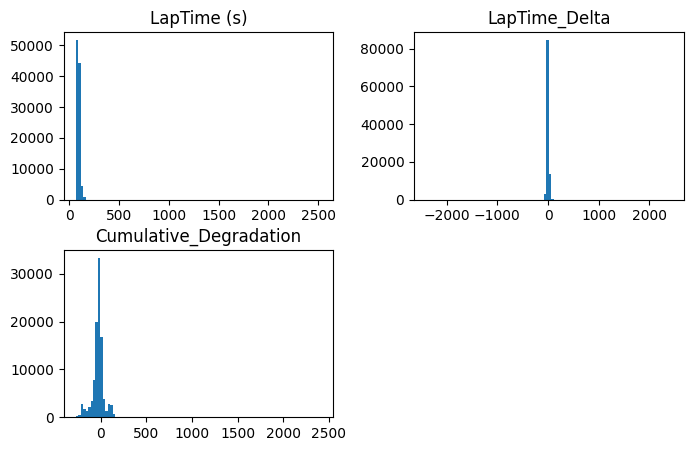

In [44]:
df[['LapTime (s)','LapTime_Delta','Cumulative_Degradation']].hist(bins=100, figsize=(8,5), grid=False)
plt.show()

Посмотрим на эти выбросы непосредственно в данных.

In [45]:
df[['LapTime (s)','LapTime_Delta','Cumulative_Degradation']].sort_values(by='LapTime (s)').tail(20)

,LapTime (s),LapTime_Delta,Cumulative_Degradation
57670,218.679,108.211,108.510
95183,226.277,125.765,66.707
97231,282.084,0.000,0.000
84634,282.084,194.203,0.000
44042,2456.330,2371.750,2349.240
44196,2458.744,2373.018,2353.476
44426,2462.721,2377.572,2353.220
44119,2468.042,2384.278,2367.618
44349,2473.884,2387.386,2370.062
44732,2478.944,2396.063,2377.531


Заменим эти большие значения времени на медианные.

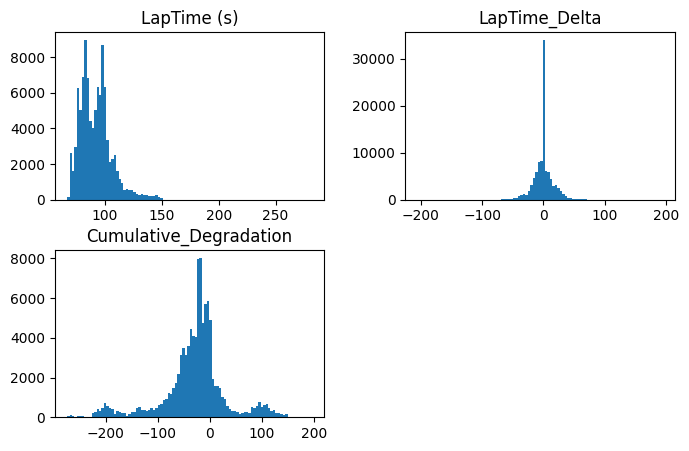

In [46]:
df.loc[df['LapTime (s)'] > 500, 'LapTime (s)'] = df['LapTime (s)'].median()
df.loc[df['LapTime_Delta'].abs() > 500, 'LapTime_Delta'] = df['LapTime_Delta'].median()
df.loc[df['Cumulative_Degradation'] > 500, 'Cumulative_Degradation'] = df['Cumulative_Degradation'].median()

# сразу посмотрим, что получилось на графиках распределения

df[['LapTime (s)','LapTime_Delta','Cumulative_Degradation']].hist(bins=100, figsize=(8,5), grid=False)
plt.show()

 #### 1.3 Корреляция числовых признаков.

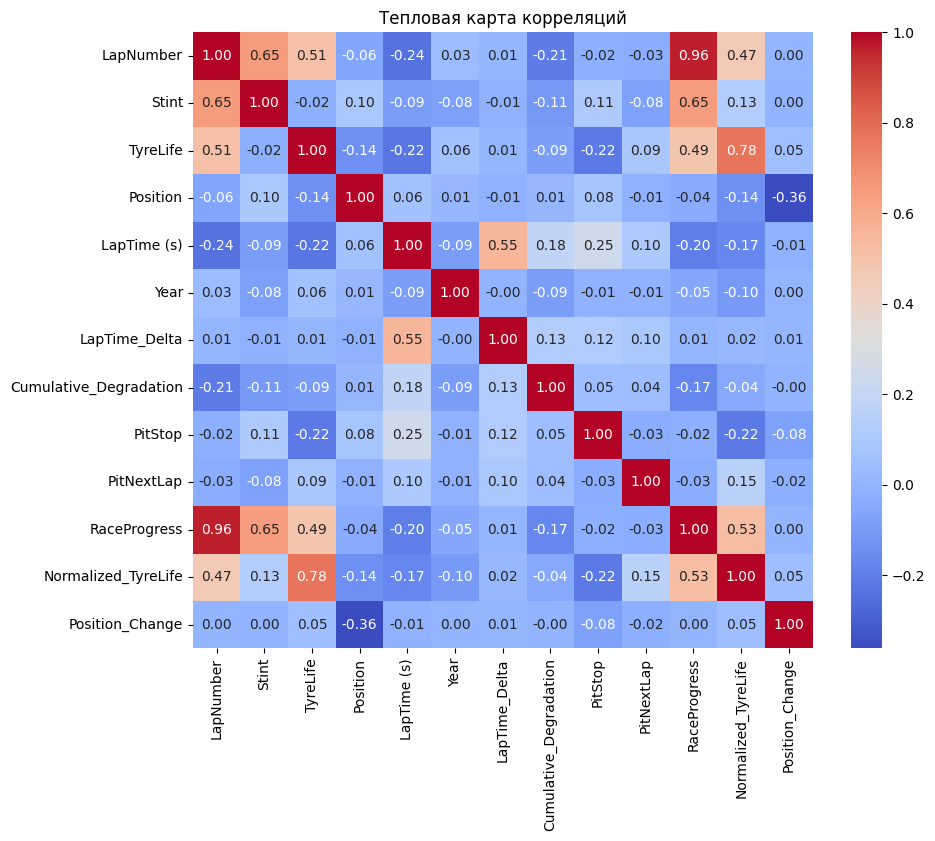

In [47]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Тепловая карта корреляций")
plt.show()

Видим высокую корреляцию признаков 'LapNumber' и 'RaceProgress', один из признаков нужно удалить

In [48]:
# удалим признак 'RaceProgress'
df = df.drop(['RaceProgress'], axis=1)

Поразмыслив, решил перевести числовой признак 'Year' в разряд категориальных. Возможно, решение неоднозначное.

In [49]:
# переведем признак 'Year' в разряд категориальных
df['Year'] = df['Year'].astype(object)
print(df['Year'].dtypes)

object


### 1.4 Сбалансированность классов целевого признака.

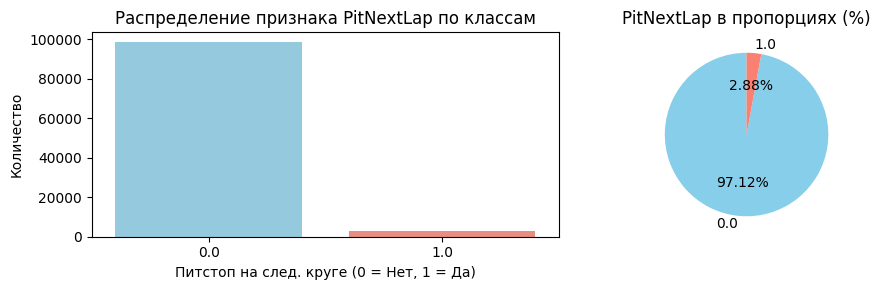

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

colors = ['skyblue', 'salmon']

sns.countplot(
    data=df,
    x='PitNextLap',
    ax=axes[0],
    palette=colors,
    hue='PitNextLap',
    legend=False
)

axes[0].set_title('Распределение признака PitNextLap по классам')
axes[0].set_xlabel('Питстоп на след. круге (0 = Нет, 1 = Да)')
axes[0].set_ylabel('Количество')

status_counts = df['PitNextLap'].value_counts()

axes[1].pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.2f%%',
    colors=colors,
    startangle=90
)

axes[1].set_title('PitNextLap в пропорциях (%)')
plt.tight_layout()
plt.show()

Наблюдаем сильную несбалансированность классов этого признака.

### 1.5 Анализ количественных признаков.

In [51]:
# выделим имена числовых признаков в виде списка для удобства дальнейшей работы, удалим из него целевой признак
types = df.dtypes
num_features = list(types[(types != 'object')].index)
num_features.remove('PitNextLap')
print(len(num_features)) # выводим количество числовых признаков
print(num_features) # список признаков

10
['LapNumber', 'Stint', 'TyreLife', 'Position', 'LapTime (s)', 'LapTime_Delta', 'Cumulative_Degradation', 'PitStop', 'Normalized_TyreLife', 'Position_Change']


Для этих числовых признаков строим гистограммы, иллюстрирующие их распределение в разрезе целевого признака.

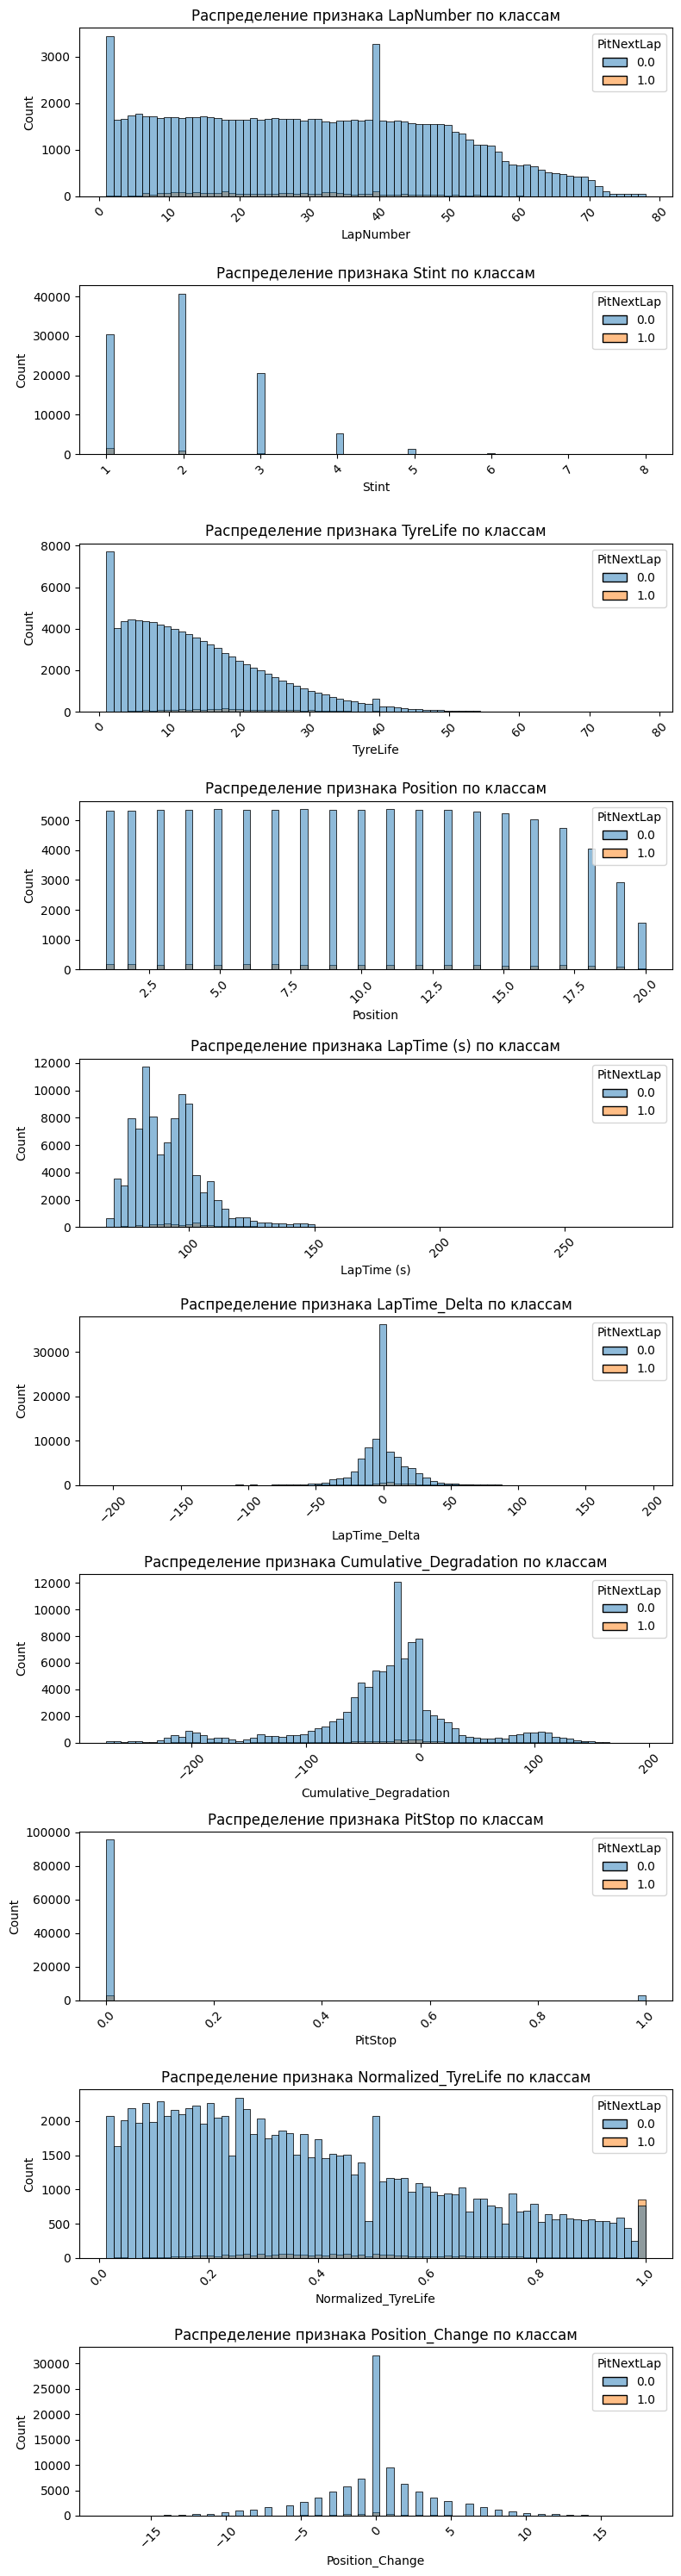

In [52]:
n = len(num_features) #количество числовых признаков
fig, axes = plt.subplots(n, 1, figsize=(8, 30)) 
#Создаем цикл для всех признаков из списка числовых признаков
for i, feature in enumerate(num_features): 
    #Строим гистограмму распределения признака 
    histplot = sns.histplot(data=df, x=feature, hue='PitNextLap', bins=75, ax=axes[i])
    histplot.set_title('Распределение признака {} по классам'.format(feature))
    histplot.xaxis.set_tick_params(rotation=45)
    
plt.tight_layout() #выравнивание графиков

ВАЖНОЕ ЗАМЕЧАНИЕ. На предпоследнем графике видим интересную зависимость у нашего целевого признака и признака 'Normalized_TyreLife'. Здесь следует сказать, что на платформе Kaggle было соревнование по схожей задаче с синтетическим датасетом, похожим на наш. В предисловии к тому соревнованию сказано буквально следующее "we intentionally remove Normalized_TyreLife which makes the prediction trivial". Глядя на наш график, можно понять, почему организаторы соревнования удалили из датасета этот признак. :)

Оценим важность числовых признаков при помощи статистического теста ANOVA (f_classif)

<Axes: title={'center': 'Наиболее важные числовые признаки'}>

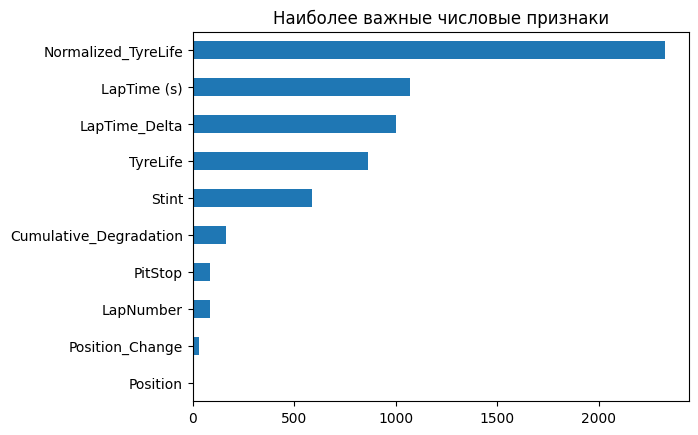

In [53]:
imp_num = pd.Series(f_classif(df[num_features], df['PitNextLap'])[0], index = num_features)
imp_num.sort_values(inplace = True)
imp_num.plot(kind = 'barh', title='Наиболее важные числовые признаки')

Видим, что признак Normalized_TyreLife действительно дает много информации о целевом признаке.

### 1.6 Анализ категориальных признаков.

In [54]:
# выделим имена категориальных признаков в виде списка для удобства дальнейшей работы
types = df.dtypes
cat_features = list(types[(types == 'object')].index)
print(len(cat_features)) # количество категориальных признаков
print(cat_features) # категориальные признаки

4
['Driver', 'Compound', 'Race', 'Year']


Построим графики, иллюстрирующие распределение целевой переменной в категориальных признаках.

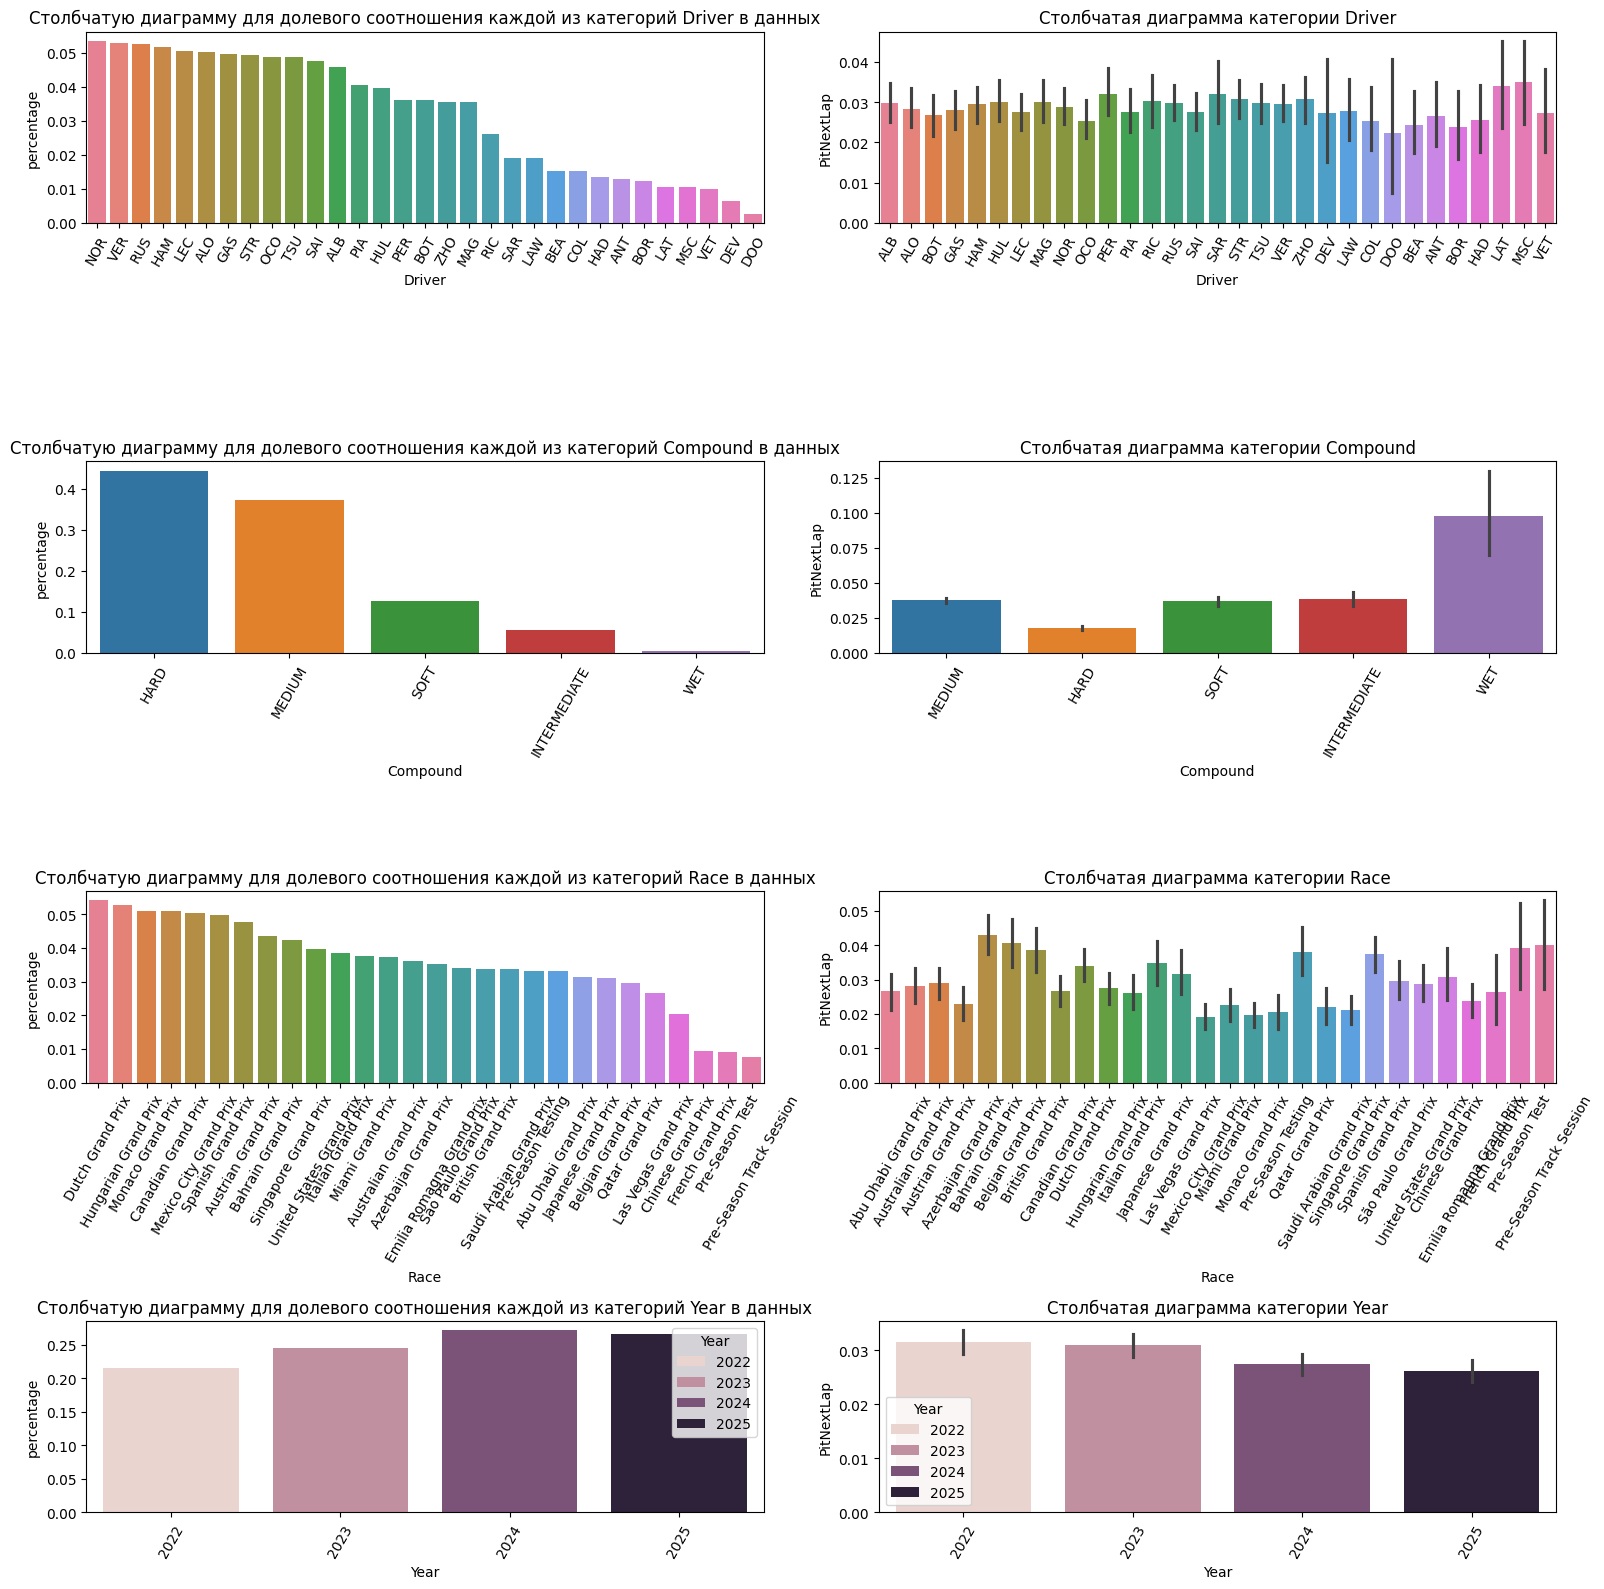

In [55]:
n = len(cat_features) #число категориальных признаков
fig, axes = plt.subplots(n, 2, figsize=(16, 16)) 
#Создаём цикл для всех признаков из списка категориальных признаков
for i, feature in enumerate(cat_features):
    #Строим количественную столбчатую диаграмму для долевого соотношения каждой из категорий в данных
    count_data = (df[feature].value_counts(normalize=True)
                  .sort_values(ascending=False)
                  .rename('percentage')
                  .reset_index())
    count_barplot = sns.barplot(data=count_data, x=feature, y='percentage', hue=feature, ax=axes[i][0])
    count_barplot.set_title('Столбчатую диаграмму для долевого соотношения каждой из категорий {} в данных'.format(feature))
    count_barplot.xaxis.set_tick_params(rotation=60)
    #Строим столбчатую диаграмму
    mean_barplot = sns.barplot(data=df, x=feature, y='PitNextLap', hue=feature, ax=axes[i][1])
    mean_barplot.set_title('Столбчатая диаграмма категории {}'.format(feature))
    mean_barplot.xaxis.set_tick_params(rotation=60)
plt.tight_layout() #выравнивание графиков

## 2 Генерация новых признаков. Стандартизация и кодирование признаков.

### 2.1 Генерация новых признаков.

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101371 entries, 0 to 101370
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Driver                  101371 non-null  object 
 1   LapNumber               101371 non-null  int64  
 2   Compound                101371 non-null  object 
 3   Stint                   101371 non-null  int64  
 4   TyreLife                101371 non-null  float64
 5   Position                101371 non-null  int64  
 6   LapTime (s)             101371 non-null  float64
 7   Race                    101371 non-null  object 
 8   Year                    101371 non-null  object 
 9   LapTime_Delta           101371 non-null  float64
 10  Cumulative_Degradation  101371 non-null  float64
 11  PitStop                 101371 non-null  int64  
 12  PitNextLap              101371 non-null  float64
 13  Normalized_TyreLife     101371 non-null  float64
 14  Position_Change     

Создадим несколько признаков на основе уже существующих числовых признаков.

In [57]:
race_length = df.groupby('Race')['LapNumber'].transform("max")
df['RemainingLaps'] = race_length - df['LapNumber']
df['TyreLifeRemainingRatio'] = df['TyreLife'] / (df['RemainingLaps']+1)
df['PositionTyreLife'] = df['Position'] * df['TyreLife']
df['LapDelta_TyreLife'] =  df['LapTime_Delta'] * df['TyreLife']
df['Stint_TyreLife'] = df['Stint'] * df['TyreLife']

### 2.2 Кодирование категориальных и стандартизация числовых признаков.

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101371 entries, 0 to 101370
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Driver                  101371 non-null  object 
 1   LapNumber               101371 non-null  int64  
 2   Compound                101371 non-null  object 
 3   Stint                   101371 non-null  int64  
 4   TyreLife                101371 non-null  float64
 5   Position                101371 non-null  int64  
 6   LapTime (s)             101371 non-null  float64
 7   Race                    101371 non-null  object 
 8   Year                    101371 non-null  object 
 9   LapTime_Delta           101371 non-null  float64
 10  Cumulative_Degradation  101371 non-null  float64
 11  PitStop                 101371 non-null  int64  
 12  PitNextLap              101371 non-null  float64
 13  Normalized_TyreLife     101371 non-null  float64
 14  Position_Change     

Кодируем категориальные признаки при помощи OneHotEncoder.

In [59]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
encoder = ce.OneHotEncoder(cols=cat_cols, use_cat_names=True) # указываем столбец для кодирования
type_bin = encoder.fit_transform(df[cat_cols]) # создаем закодированные признаки
df = pd.concat([df, type_bin], axis=1) # добавляем новые признаки в датафрейм
df.drop(cat_cols, axis=1, inplace=True) # удаляем старые ненужные
df.head() # смотрим результат

,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,Normalized_TyreLife,...,Race_United States Grand Prix,Race_Chinese Grand Prix,Race_Emilia Romagna Grand Prix,Race_French Grand Prix,Race_Pre-Season Test,Race_Pre-Season Track Session,Year_2023.0,Year_2024.0,Year_2025.0,Year_2022.0
0,1,1,2.0,17,100.625,0.000,0.000,0,0.0,0.117647,...,0,0,0,0,0,0,1,0,0,0
1,2,1,3.0,18,93.560,-7.065,-7.065,0,0.0,0.176471,...,0,0,0,0,0,0,1,0,0,0
2,3,1,4.0,18,91.768,-1.792,-8.857,0,0.0,0.235294,...,0,0,0,0,0,0,1,0,0,0
3,4,1,5.0,18,91.591,-0.177,-9.034,0,0.0,0.294118,...,0,0,0,0,0,0,1,0,0,0
4,5,1,6.0,18,91.422,-0.169,-9.203,0,0.0,0.352941,...,0,0,0,0,0,0,1,0,0,0


После кодирования категориальных признаков можем оценить их важность для целевой переменной при помощи статистического теста Хи-квадрат.

<Axes: title={'center': '32 наиболее важных признака'}>

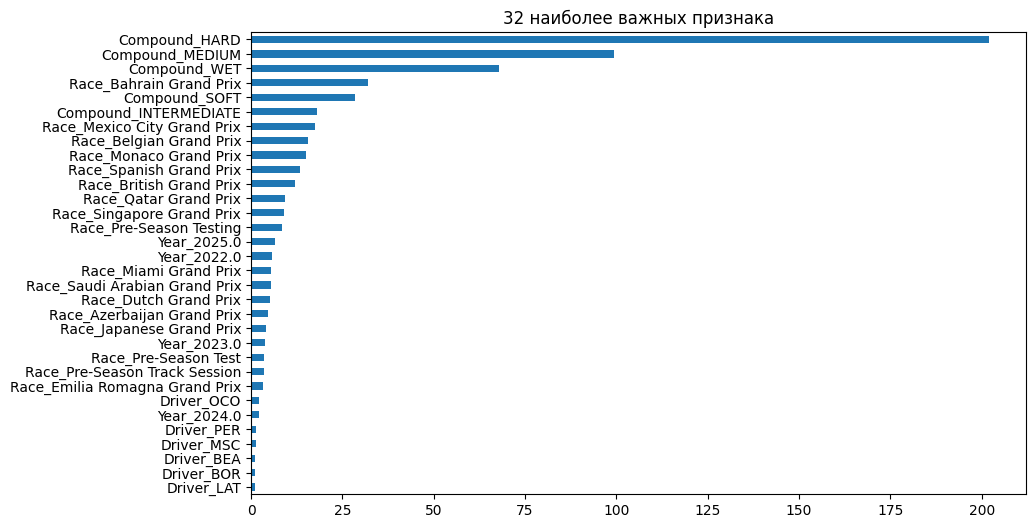

In [60]:
# проводим тест и смотрим результат
cat_columns_list = type_bin.columns.tolist()
imp_cat = pd.Series(chi2(type_bin, df['PitNextLap'])[0], index=cat_columns_list)
imp_cat.sort_values(inplace = True)
imp_cat[-32:].plot(kind = 'barh', figsize=(10,6), title='32 наиболее важных признака')

Стандартизируем данные при помощи MinMaxScaler.
Применил стандартизатор на весь датасет, не стал выделялять числовые признаки, поскольку закодированные категориальные при этом не искажаются.
В общем случае, это, вероятно, не корректно.

In [61]:
col_names = list(df.columns)
# инициализируем нормализатор MinMaxScaler
mm_scaler = preprocessing.MinMaxScaler()

# кодируем исходный датасет
df_mm = mm_scaler.fit_transform(df)

# Преобразуем промежуточный датасет в полноценный датафрейм для визуализации
df_mm = pd.DataFrame(df_mm, columns=col_names)
df_mm.describe() # посмотрим результат

,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,Normalized_TyreLife,...,Race_United States Grand Prix,Race_Chinese Grand Prix,Race_Emilia Romagna Grand Prix,Race_French Grand Prix,Race_Pre-Season Test,Race_Pre-Season Track Session,Year_2023.0,Year_2024.0,Year_2025.0,Year_2022.0
count,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,...,101371.000000,101371.00000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000,101371.000000
mean,0.382401,0.149485,0.175965,0.461007,0.117154,0.513268,0.519003,0.028815,0.028815,0.378554,...,0.039745,0.02044,0.035197,0.009322,0.009056,0.007625,0.245770,0.271843,0.266743,0.215644
std,0.235675,0.135542,0.133940,0.284550,0.065154,0.039839,0.134438,0.167287,0.167287,0.263281,...,0.195361,0.14150,0.184279,0.096101,0.094731,0.086991,0.430545,0.444912,0.442259,0.411270
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.181818,0.000000,0.077922,0.210526,0.069786,0.495654,0.474185,0.000000,0.000000,0.161666,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.376623,0.142857,0.155844,0.473684,0.112311,0.513721,0.536509,0.000000,0.000000,0.324675,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.571429,0.285714,0.246753,0.684211,0.150371,0.528032,0.574569,0.000000,0.000000,0.556818,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [62]:
# Сохраним нормализатор в файл pickle
with open("web/app/models/mm_scaler.csv", "wb") as f:
    pickle.dump(mm_scaler, f)

In [63]:
# Сохраним кодировщик в файл pickle
with open("web/app/models/encoder.csv", "wb") as f:
    pickle.dump(encoder, f)

In [64]:
# Сохраним очищенные данные в CSV-файл
df_mm.to_csv("data/cleaned_data.csv", index=False)

### Краткие выводы по разведывательному анализу.

В это части дипломной работы мы проделали следующее:
* Произвели первичный анализ данных.
* Избавились от пропусков.
* Избавились от выбросов.
* Провели корреляционный анализ числовых признаков.
* Посмотрели на распределение числовых признаков.
* Провели анализ категориальных переменных.
* Создали несколько новых признаков из уже имеющихся.
* Провели кодирование категориальных и стандартизацию числовых признаков.
* Сохранили предобработанный датасет в отдельный файл.
* Сохранили в отдельные файлы кодировщик и стандартизатор.